In [ ]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("ananthu017/emotion-detection-fer")

print("Path to dataset files:", path)


100%|██████████| 65.2M/65.2M [00:05<00:00, 13.2MB/s]

Extracting files...


Path to dataset files: /root/.cache/kagglehub/datasets/ananthu017/emotion-detection-fer/versions/1


In [ ]:
import os

for root, dirs, files in os.walk(path):
    level = root.replace(path, "").count(os.sep)

    if level > 2:
        dirs[:] = []
        continue

    print("  " * level + os.path.basename(root) + "/")

    for file in files[:5]:
        print("  " * (level + 1) + file)

1/
  train/
    happy/
      im1104.png
      im4335.png
      im2806.png
      im4114.png
      im6021.png
    disgusted/
      im351.png
      im98.png
      im53.png
      im271.png
      im405.png
    fearful/
      im1104.png
      im2806.png
      im1808.png
      im2872.png
      im866.png
    sad/
      im1104.png
      im4335.png
      im2806.png
      im4114.png
      im1808.png
    neutral/
      im1104.png
      im4335.png
      im2806.png
      im4114.png
      im1808.png
    angry/
      im1104.png
      im2806.png
      im1808.png
      im2872.png
      im866.png
    surprised/
      im1104.png
      im2806.png
      im1808.png
      im2872.png
      im866.png
  test/
    happy/
      im1104.png
      im866.png
      im351.png
      im575.png
      im664.png
    disgusted/
      im98.png
      im53.png
      im102.png
      im106.png
      im55.png
    fearful/
      im866.png
      im351.png
      im575.png
      im664.png
      im767.png
    sad/
      im1104.png
     

In [ ]:
from collections import Counter
from pathlib import Path

image_extensions = {".jpg", ".jpeg", ".png", ".bmp"}

image_files = [
    p for p in Path(path).rglob("*")
    if p.is_file() and p.suffix.lower() in image_extensions
]

print("Total images:", len(image_files))

folder_counts = Counter(p.parent.name for p in image_files)

for folder, count in sorted(folder_counts.items()):
    print(f"{folder}: {count}")

Total images: 35887
angry: 4953
disgusted: 547
fearful: 5121
happy: 8989
neutral: 6198
sad: 6077
surprised: 4002


In [ ]:
import cv2

In [ ]:
from pathlib import Path

dataset_path = Path(path)

for split in ["train", "test"]:
    split_path = dataset_path / split
    print(f"\n{split.upper()}")

    if not split_path.exists():
        print(f"{split} folder not found")
        continue

    for emotion_dir in sorted(split_path.iterdir()):
        if emotion_dir.is_dir():
            count = sum(
                1 for f in emotion_dir.iterdir()
                if f.suffix.lower() in {".png", ".jpg", ".jpeg"}
            )
            print(f"{emotion_dir.name}: {count}")


TRAIN
angry: 3995
disgusted: 436
fearful: 4097
happy: 7215
neutral: 4965
sad: 4830
surprised: 3171

TEST
angry: 958
disgusted: 111
fearful: 1024
happy: 1774
neutral: 1233
sad: 1247
surprised: 831


In [ ]:
%pip install opencv-python mediapipe matplotlib

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 41.5/41.5 MB 12.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 137.7/137.7 kB 15.6 MB/s eta 0:00:00
  Attempting uninstall: absl-py
    Found existing installation: absl-py 1.4.0
    Uninstalling absl-py-1.4.0:
      Successfully uninstalled absl-py-1.4.0


In [15]:
import numpy as np, tensorflow as tf
import matplotlib.pyplot as plt
from pathlib import Path

print("TensorFlow:", tf.__version__, "| GPUs:", tf.config.list_physical_devices("GPU"))

root = Path(path)
IMG, BATCH = 112, 128
AUTOTUNE = tf.data.AUTOTUNE

common = dict(color_mode="rgb",          # gray PNG -> 3 channels automatically
              image_size=(IMG, IMG),     # resize 48x48 -> 112x112
              label_mode="categorical",
              seed=42)

train_ds = tf.keras.utils.image_dataset_from_directory(
    str(root / "train"), validation_split=0.1, subset="training",
    batch_size=BATCH, **common)
val_ds = tf.keras.utils.image_dataset_from_directory(
    str(root / "train"), validation_split=0.1, subset="validation",
    batch_size=BATCH, **common)
test_ds = tf.keras.utils.image_dataset_from_directory(
    str(root / "test"), shuffle=False, batch_size=BATCH,
    color_mode="rgb", image_size=(IMG, IMG), label_mode="categorical")

class_names = train_ds.class_names
print("Classes:", class_names)

train_ds = train_ds.prefetch(AUTOTUNE)
val_ds   = val_ds.prefetch(AUTOTUNE)
test_ds  = test_ds.prefetch(AUTOTUNE)

# Class weights (compensate for the tiny "disgusted" class)
counts = np.array([len(list((root / "train" / c).glob("*"))) for c in class_names])
class_weight = {i: counts.sum() / (len(counts) * n) for i, n in enumerate(counts)}
print(dict(zip(class_names, counts)))
print({class_names[i]: round(w, 2) for i, w in class_weight.items()})

TensorFlow: 2.21.0 | GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Found 28709 files belonging to 7 classes.
Using 25839 files for training.
Found 28709 files belonging to 7 classes.
Using 2870 files for validation.
Found 7178 files belonging to 7 classes.
Classes: ['angry', 'disgusted', 'fearful', 'happy', 'neutral', 'sad', 'surprised']
{'angry': np.int64(3995), 'disgusted': np.int64(436), 'fearful': np.int64(4097), 'happy': np.int64(7215), 'neutral': np.int64(4965), 'sad': np.int64(4830), 'surprised': np.int64(3171)}
{'angry': np.float64(1.03), 'disgusted': np.float64(9.41), 'fearful': np.float64(1.0), 'happy': np.float64(0.57), 'neutral': np.float64(0.83), 'sad': np.float64(0.85), 'surprised': np.float64(1.29)}


In [17]:
from tensorflow.keras import layers, models

augment = tf.keras.Sequential([
    layers.RandomFlip("horizontal"),
    layers.RandomRotation(0.03),
    layers.RandomZoom(0.1),
    layers.RandomContrast(0.2),
], name="augmentation")


base = tf.keras.applications.EfficientNetB0(
    include_top=False, weights="imagenet", input_shape=(IMG, IMG, 3))
base.trainable = False

inputs  = layers.Input(shape=(IMG, IMG, 3))
x = augment(inputs)
x = base(x, training=False)
x = layers.GlobalAveragePooling2D()(x)
x = layers.Dropout(0.3)(x)
outputs = layers.Dense(len(class_names), activation="softmax")(x)
model = models.Model(inputs, outputs)

model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-3),
    loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
    metrics=["accuracy"])
model.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_4 (InputLayer)      │ (None, 112, 112, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ augmentation (Sequential)       │ (None, 112, 112, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 4, 4, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 1280)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 1280)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 7)              │         8,967 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 4,058,538 (15.48 MB)

 Trainable params: 8,967 (35.03 KB)

 Non-trainable params: 4,049,571 (15.45 MB)

In [18]:
callbacks = [
    tf.keras.callbacks.ModelCheckpoint("best_emotion_model.keras",
        monitor="val_accuracy", save_best_only=True, verbose=1),
    tf.keras.callbacks.EarlyStopping(monitor="val_accuracy",
        patience=4, restore_best_weights=True),
    tf.keras.callbacks.ReduceLROnPlateau(monitor="val_loss",
        factor=0.5, patience=2, verbose=1),
]


h1 = model.fit(train_ds, validation_data=val_ds, epochs=6,
               class_weight=class_weight, callbacks=callbacks)

base.trainable = True
model.compile(
    optimizer=tf.keras.optimizers.Adam(1e-4),
    loss=tf.keras.losses.CategoricalCrossentropy(label_smoothing=0.1),
    metrics=["accuracy"])
h2 = model.fit(train_ds, validation_data=val_ds, epochs=20,
               class_weight=class_weight, callbacks=callbacks)

Epoch 1/6
202/202 ━━━━━━━━━━━━━━━━━━━━ 0s 79ms/step - accuracy: 0.2628 - loss: 1.8739
Epoch 1: val_accuracy improved from None to 0.41603, saving model to best_emotion_model.keras

Epoch 1: finished saving model to best_emotion_model.keras
202/202 ━━━━━━━━━━━━━━━━━━━━ 37s 109ms/step - accuracy: 0.3060 - loss: 1.8007 - val_accuracy: 0.4160 - val_loss: 1.6444 - learning_rate: 0.0010
Epoch 2/6
202/202 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step - accuracy: 0.3750 - loss: 1.6967
Epoch 2: val_accuracy improved from 0.41603 to 0.43902, saving model to best_emotion_model.keras

Epoch 2: finished saving model to best_emotion_model.keras
202/202 ━━━━━━━━━━━━━━━━━━━━ 21s 105ms/step - accuracy: 0.3747 - loss: 1.6889 - val_accuracy: 0.4390 - val_loss: 1.5951 - learning_rate: 0.0010
Epoch 3/6
202/202 ━━━━━━━━━━━━━━━━━━━━ 0s 85ms/step - accuracy: 0.4028 - loss: 1.6444
Epoch 3: val_accuracy improved from 0.43902 to 0.44913, saving model to best_emotion_model.keras

Epoch 3: finished saving model to best_emotio

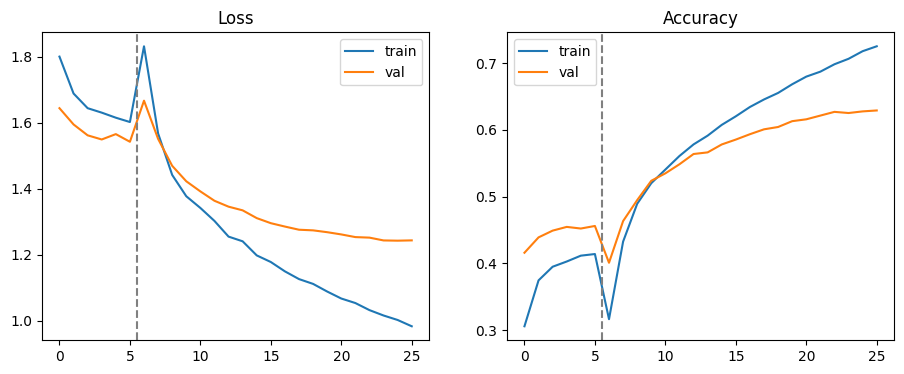

In [19]:
acc  = h1.history["accuracy"]     + h2.history["accuracy"]
vacc = h1.history["val_accuracy"] + h2.history["val_accuracy"]
loss  = h1.history["loss"]     + h2.history["loss"]
vloss = h1.history["val_loss"] + h2.history["val_loss"]

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].plot(loss, label="train"); ax[0].plot(vloss, label="val"); ax[0].set_title("Loss"); ax[0].legend()
ax[1].plot(acc, label="train");  ax[1].plot(vacc, label="val");  ax[1].set_title("Accuracy"); ax[1].legend()
for a in ax: a.axvline(len(h1.history["loss"]) - 0.5, ls="--", c="gray")  # phase boundary
plt.show()

57/57 ━━━━━━━━━━━━━━━━━━━━ 9s 122ms/step
              precision    recall  f1-score   support

       angry      0.591     0.523     0.555       958
   disgusted      0.497     0.757     0.600       111
     fearful      0.544     0.386     0.451      1024
       happy      0.875     0.827     0.850      1774
     neutral      0.536     0.702     0.608      1233
         sad      0.520     0.536     0.528      1247
   surprised      0.750     0.777     0.764       831

    accuracy                          0.645      7178
   macro avg      0.616     0.644     0.622      7178
weighted avg      0.650     0.645     0.643      7178



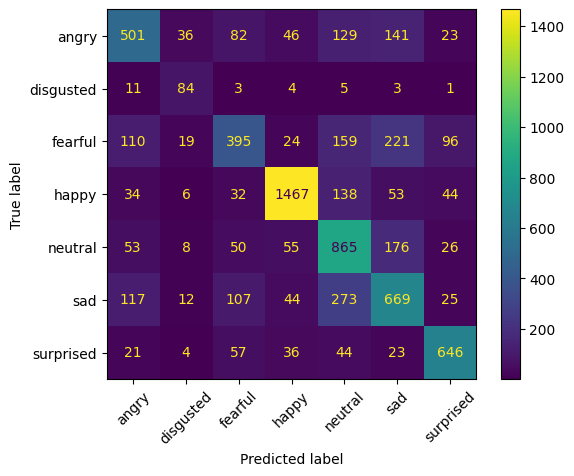

In [20]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

model = tf.keras.models.load_model("best_emotion_model.keras")

y_true = np.concatenate([np.argmax(y, axis=1) for _, y in test_ds])
y_pred = np.argmax(model.predict(test_ds), axis=1)

print(classification_report(y_true, y_pred, target_names=class_names, digits=3))
ConfusionMatrixDisplay(confusion_matrix(y_true, y_pred),
                       display_labels=class_names).plot(xticks_rotation=45)
plt.show()